# Notebook 04: Carport Data Exploratie 

In [1]:
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt

DATA_DIR = Path.cwd().parent / "locatie_data"

In [2]:
df_carport = pd.read_parquet(
    DATA_DIR / "carport.parquet"
)

In [3]:
df_carport.head()

,timestamp,CO2EQ,CTYPE,ENAME,ETYPE,source_zip,source_csv,source_folder,CTYPEC,ESTYPE,...,CO2_EXP,CO2_IMP,ENE_EXP,ENE_IMP,COST,COST_EXP,COST_IMP,ENE_CNT_EXP,ENE_CNT_IMP,PRICE
0,2024-03-08 01:00:00+01:00,NaN,electricity,hoofdaansluiting-e4393cd3dfdb,powermeter,240308_hoofdaansluiting-e4393cd3dfdb_854d89ad9...,240308_hoofdaansluiting-e4393cd3dfdb_854d89ad9...,hoofdaansluiting-e4393cd3dfdb,supply,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2024-03-08 01:00:00+01:00,NaN,electricity,laadpaal1-e4393cd3dfdb,evcharger,240308_laadpaal1-e4393cd3dfdb_ef67dd7cc10861d9...,240308_laadpaal1-e4393cd3dfdb_ef67dd7cc10861d9...,laadpaal1-e4393cd3dfdb,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2024-03-08 01:00:00+01:00,NaN,electricity,laadpaal2-e4393cd3dfdb,evcharger,240308_laadpaal2-e4393cd3dfdb_ef67dd7cc10861d9...,240308_laadpaal2-e4393cd3dfdb_ef67dd7cc10861d9...,laadpaal2-e4393cd3dfdb,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2024-03-08 01:00:00+01:00,NaN,electricity,laadpaal3-e4393cd3dfdb,evcharger,240308_laadpaal3-e4393cd3dfdb_ef67dd7cc10861d9...,240308_laadpaal3-e4393cd3dfdb_ef67dd7cc10861d9...,laadpaal3-e4393cd3dfdb,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2024-03-08 01:00:00+01:00,NaN,electricity,overigverbruik-e4393cd3dfdb,powermeter,240308_overigverbruik-e4393cd3dfdb_a7612155098...,240308_overigverbruik-e4393cd3dfdb_a7612155098...,overigverbruik-e4393cd3dfdb,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Algemene controle

In [4]:
print("Shape:", df_carport.shape)
print("Chronologisch:", df_carport["timestamp"].is_monotonic_increasing)

df_carport.info()

Shape: (4888431, 25)
Chronologisch: True
<class 'pandas.DataFrame'>
RangeIndex: 4888431 entries, 0 to 4888430
Data columns (total 25 columns):
 #   Column         Dtype                           
---  ------         -----                           
 0   timestamp      datetime64[us, Europe/Amsterdam]
 1   CO2EQ          float64                         
 2   CTYPE          str                             
 3   ENAME          str                             
 4   ETYPE          str                             
 5   source_zip     str                             
 6   source_csv     str                             
 7   source_folder  str                             
 8   CTYPEC         str                             
 9   ESTYPE         str                             
 10  forecast.ENE   float64                         
 11  forecast.POW   float64                         
 12  ENE            float64                         
 13  POW            float64                         
 14  CO2 

In [5]:
df_carport["ENAME"].value_counts()

ENAME
totaalverbruik-e4393cd3dfdb            361138
laadpaal2-e4393cd3dfdb                 360889
laadpaal1-e4393cd3dfdb                 360517
hoofdaansluiting-e4393cd3dfdb          358041
overigverbruik-e4393cd3dfdb            356967
laadpaal3-e4393cd3dfdb                 353343
zonnepanelen-e4393cd3dfdb              345473
wijktotaalverbruik-e4393cd3dfdb        318470
wijkvirtuelehoofdmeter-e4393cd3dfdb    318195
wijktotaleopwek-e4393cd3dfdb           309497
laadpaalbus-e4393cd3dfdb               282308
laadpaaltesla-e4393cd3dfdb             281698
victronaccu-e4393cd3dfdb               259754
co2ele_combined                        158933
priceele_c911efafaa                    147634
odectprice_c911efafaa                   95109
laadpaal4-e4393cd3dfdb                  92220
laadpaal5-e4393cd3dfdb                  92220
forec-totaalverbruik-e4393cd3dfdb       17294
forec-zonnepanelen-e4393cd3dfdb         17294
priceele_123456                          1437
Name: count, dtype: int64

In [6]:
ingevulde_kolommen_per_ename = (
    df_carport.groupby("ENAME").count()
)

ingevulde_kolommen_per_ename

,timestamp,CO2EQ,CTYPE,ETYPE,source_zip,source_csv,source_folder,CTYPEC,ESTYPE,forecast.ENE,...,CO2_EXP,CO2_IMP,ENE_EXP,ENE_IMP,COST,COST_EXP,COST_IMP,ENE_CNT_EXP,ENE_CNT_IMP,PRICE
ENAME,,,,,,,,,,,,,,,,,,,,,
co2ele_combined,158933,158933,158933,158933,158933,158933,158933,0,0,0,...,0,0,0,0,0,0,0,0,0,0
forec-totaalverbruik-e4393cd3dfdb,17294,0,17294,17294,17294,17294,17294,17294,17294,8647,...,0,0,0,0,0,0,0,0,0,0
forec-zonnepanelen-e4393cd3dfdb,17294,0,17294,17294,17294,17294,17294,17294,17294,8647,...,0,0,0,0,0,0,0,0,0,0
hoofdaansluiting-e4393cd3dfdb,358041,0,358041,358041,358041,358041,358041,219821,0,0,...,78271,84446,145952,152130,138218,137072,137071,141751,141749,0
laadpaal1-e4393cd3dfdb,360517,0,360517,360517,360517,360517,360517,138108,0,0,...,0,70559,0,138235,129460,0,133599,0,138277,0
laadpaal2-e4393cd3dfdb,360889,0,360889,360889,360889,360889,360889,138107,0,0,...,0,70461,0,138135,129245,0,133501,0,138177,0
laadpaal3-e4393cd3dfdb,353343,0,353343,353343,353343,353343,353343,134340,0,0,...,0,66413,0,131748,124566,0,127124,0,131789,0
laadpaal4-e4393cd3dfdb,92220,0,92220,92220,92220,92220,92220,43790,0,0,...,0,6958,0,48416,40706,0,43781,0,48429,0
laadpaal5-e4393cd3dfdb,92220,0,92220,92220,92220,92220,92220,43790,0,0,...,0,6958,0,48417,40706,0,43782,0,48430,0


### Overzicht van de meetreeksen

In [7]:
# maakt per ENAME een samenvatting vd timestamps 
overzicht = (df_carport.groupby("ENAME").agg(
        aantal_rijen=("timestamp", "size"), # telt hoeveel rijen er per ENAME zijn 
        unieke_timestamps=("timestamp", "nunique"), # telt hoeveel verschillende timestamps er per ENAME zijn 
        eerste_meting=("timestamp", "min"), # eerste timestamp die voorkomt per ENAME 
        laatste_meting=("timestamp", "max") # laatste timestamp die voorkomt per ENAME
    )
)

# berekent hoeveel extra rijen er zijn doordat timestamps vaker dan 1 keer voorkomen 
overzicht["dubbele_timestamps"] = (overzicht["aantal_rijen"] - overzicht["unieke_timestamps"])

overzicht.sort_values("aantal_rijen", ascending=False)

,aantal_rijen,unieke_timestamps,eerste_meting,laatste_meting,dubbele_timestamps
ENAME,,,,,
totaalverbruik-e4393cd3dfdb,361138,222913,2024-03-08 01:00:00+01:00,2026-09-07 08:05:00+02:00,138225
laadpaal2-e4393cd3dfdb,360889,222781,2024-03-08 01:00:00+01:00,2026-09-07 08:05:00+02:00,138108
laadpaal1-e4393cd3dfdb,360517,222408,2024-03-08 01:00:00+01:00,2026-09-07 08:05:00+02:00,138109
hoofdaansluiting-e4393cd3dfdb,358041,219820,2024-03-08 01:00:00+01:00,2026-09-07 08:05:00+02:00,138221
overigverbruik-e4393cd3dfdb,356967,220886,2024-03-08 01:00:00+01:00,2026-09-07 08:05:00+02:00,136081
laadpaal3-e4393cd3dfdb,353343,219002,2024-03-08 01:00:00+01:00,2026-09-07 08:05:00+02:00,134341
zonnepanelen-e4393cd3dfdb,345473,207287,2024-03-08 01:05:00+01:00,2026-09-07 08:05:00+02:00,138186
wijktotaalverbruik-e4393cd3dfdb,318470,182389,2024-03-08 21:55:00+01:00,2026-09-07 08:05:00+02:00,136081
wijkvirtuelehoofdmeter-e4393cd3dfdb,318195,182114,2024-03-09 20:55:00+01:00,2026-09-07 08:05:00+02:00,136081


### Totaalverbruik bekijken

In [8]:
TOTAALVERBRUIK = "totaalverbruik-e4393cd3dfdb"

# aparte dataframe met alleen de rijen van totaalverbruik
df_totaal = (df_carport[df_carport["ENAME"] == TOTAALVERBRUIK].copy()
             .sort_values("timestamp").reset_index(drop=True)
)

print("Aantal rijen:", len(df_totaal))
print("Unieke timestamps:", df_totaal["timestamp"].nunique())

# berekent hoeveel extra rijen er zijn doordat timestamps vaker voorkomen
print("Dubbele timestamps:",
    len(df_totaal) - df_totaal["timestamp"].nunique()
)

df_totaal.head()

Aantal rijen: 361138
Unieke timestamps: 222913
Dubbele timestamps: 138225


,timestamp,CO2EQ,CTYPE,ENAME,ETYPE,source_zip,source_csv,source_folder,CTYPEC,ESTYPE,...,CO2_EXP,CO2_IMP,ENE_EXP,ENE_IMP,COST,COST_EXP,COST_IMP,ENE_CNT_EXP,ENE_CNT_IMP,PRICE
0,2024-03-08 01:00:00+01:00,NaN,electricity,totaalverbruik-e4393cd3dfdb,powermeter,240308_totaalverbruik-e4393cd3dfdb_12b7271b3b6...,240308_totaalverbruik-e4393cd3dfdb_12b7271b3b6...,totaalverbruik-e4393cd3dfdb,consumption,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2024-03-08 01:05:00+01:00,NaN,electricity,totaalverbruik-e4393cd3dfdb,powermeter,240308_totaalverbruik-e4393cd3dfdb_12b7271b3b6...,240308_totaalverbruik-e4393cd3dfdb_12b7271b3b6...,totaalverbruik-e4393cd3dfdb,consumption,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2024-03-08 01:10:00+01:00,NaN,electricity,totaalverbruik-e4393cd3dfdb,powermeter,240308_totaalverbruik-e4393cd3dfdb_12b7271b3b6...,240308_totaalverbruik-e4393cd3dfdb_12b7271b3b6...,totaalverbruik-e4393cd3dfdb,consumption,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2024-03-08 01:15:00+01:00,NaN,electricity,totaalverbruik-e4393cd3dfdb,powermeter,240308_totaalverbruik-e4393cd3dfdb_12b7271b3b6...,240308_totaalverbruik-e4393cd3dfdb_12b7271b3b6...,totaalverbruik-e4393cd3dfdb,consumption,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2024-03-08 01:20:00+01:00,NaN,electricity,totaalverbruik-e4393cd3dfdb,powermeter,240308_totaalverbruik-e4393cd3dfdb_12b7271b3b6...,240308_totaalverbruik-e4393cd3dfdb_12b7271b3b6...,totaalverbruik-e4393cd3dfdb,consumption,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [9]:
df_dubbel = (df_totaal[df_totaal["timestamp"].duplicated(keep=False)].sort_values("timestamp"))

df_dubbel

,timestamp,CO2EQ,CTYPE,ENAME,ETYPE,source_zip,source_csv,source_folder,CTYPEC,ESTYPE,...,CO2_EXP,CO2_IMP,ENE_EXP,ENE_IMP,COST,COST_EXP,COST_IMP,ENE_CNT_EXP,ENE_CNT_IMP,PRICE
59080,2024-10-05 20:10:00+02:00,NaN,electricity,totaalverbruik-e4393cd3dfdb,powermeter,241005_totaalverbruik-e4393cd3dfdb_182475cc0ac...,241005_totaalverbruik-e4393cd3dfdb_182475cc0ac...,totaalverbruik-e4393cd3dfdb,consumption,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
59081,2024-10-05 20:10:00+02:00,NaN,electricity,totaalverbruik-e4393cd3dfdb,powermeter,241005_totaalverbruik-e4393cd3dfdb_182475cc0ac...,241005_totaalverbruik-e4393cd3dfdb_182475cc0ac...,totaalverbruik-e4393cd3dfdb,consumption,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
80037,2025-01-14 09:20:00+01:00,NaN,electricity,totaalverbruik-e4393cd3dfdb,powermeter,250114_totaalverbruik-e4393cd3dfdb_1e06bd2cb94...,250114_totaalverbruik-e4393cd3dfdb_1e06bd2cb94...,totaalverbruik-e4393cd3dfdb,NaN,NaN,...,NaN,NaN,NaN,NaN,-0.000621,NaN,NaN,NaN,NaN,NaN
80038,2025-01-14 09:20:00+01:00,NaN,electricity,totaalverbruik-e4393cd3dfdb,powermeter,250114_totaalverbruik-e4393cd3dfdb_1e06bd2cb94...,250114_totaalverbruik-e4393cd3dfdb_1e06bd2cb94...,totaalverbruik-e4393cd3dfdb,consumption,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,35447531.0,NaN
80039,2025-01-14 09:25:00+01:00,NaN,electricity,totaalverbruik-e4393cd3dfdb,powermeter,250114_totaalverbruik-e4393cd3dfdb_1e06bd2cb94...,250114_totaalverbruik-e4393cd3dfdb_1e06bd2cb94...,totaalverbruik-e4393cd3dfdb,NaN,NaN,...,NaN,NaN,NaN,NaN,0.005844,0.0,0.005844,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
356507,2026-06-20 03:45:00+02:00,NaN,electricity,totaalverbruik-e4393cd3dfdb,powermeter,260620_totaalverbruik-e4393cd3dfdb_540aefae02d...,260620_totaalverbruik-e4393cd3dfdb_540aefae02d...,totaalverbruik-e4393cd3dfdb,consumption,NaN,...,0.0,0.0,0.0,0.0,NaN,NaN,NaN,0.0,19128467.0,NaN
356508,2026-06-20 03:50:00+02:00,NaN,electricity,totaalverbruik-e4393cd3dfdb,powermeter,260620_totaalverbruik-e4393cd3dfdb_540aefae02d...,260620_totaalverbruik-e4393cd3dfdb_540aefae02d...,totaalverbruik-e4393cd3dfdb,NaN,NaN,...,NaN,NaN,NaN,NaN,0.000000,0.0,0.000000,NaN,NaN,NaN
356509,2026-06-20 03:50:00+02:00,NaN,electricity,totaalverbruik-e4393cd3dfdb,powermeter,260620_totaalverbruik-e4393cd3dfdb_540aefae02d...,260620_totaalverbruik-e4393cd3dfdb_540aefae02d...,totaalverbruik-e4393cd3dfdb,consumption,NaN,...,0.0,0.0,0.0,0.0,NaN,NaN,NaN,0.0,19128467.0,NaN
356510,2026-06-20 03:55:00+02:00,NaN,electricity,totaalverbruik-e4393cd3dfdb,powermeter,260620_totaalverbruik-e4393cd3dfdb_540aefae02d...,260620_totaalverbruik-e4393cd3dfdb_540aefae02d...,totaalverbruik-e4393cd3dfdb,consumption,NaN,...,0.0,0.0,0.0,0.0,NaN,NaN,NaN,0.0,19128467.0,NaN


### POW bekijken

In [10]:
df_totaal[["timestamp", "POW"]].head()

,timestamp,POW
0,2024-03-08 01:00:00+01:00,786.222222
1,2024-03-08 01:05:00+01:00,3108.181818
2,2024-03-08 01:10:00+01:00,3253.111111
3,2024-03-08 01:15:00+01:00,3249.264706
4,2024-03-08 01:20:00+01:00,1446.435897


In [11]:
print("Ontbrekende POW:", df_totaal["POW"].isna().sum())

Ontbrekende POW: 152752


In [12]:
df_totaal['POW'].describe().T

count    208386.000000
mean       1907.489846
std        3634.913964
min      -25072.572193
25%          39.120849
50%         167.578095
75%        1114.618921
max       35694.647059
Name: POW, dtype: float64

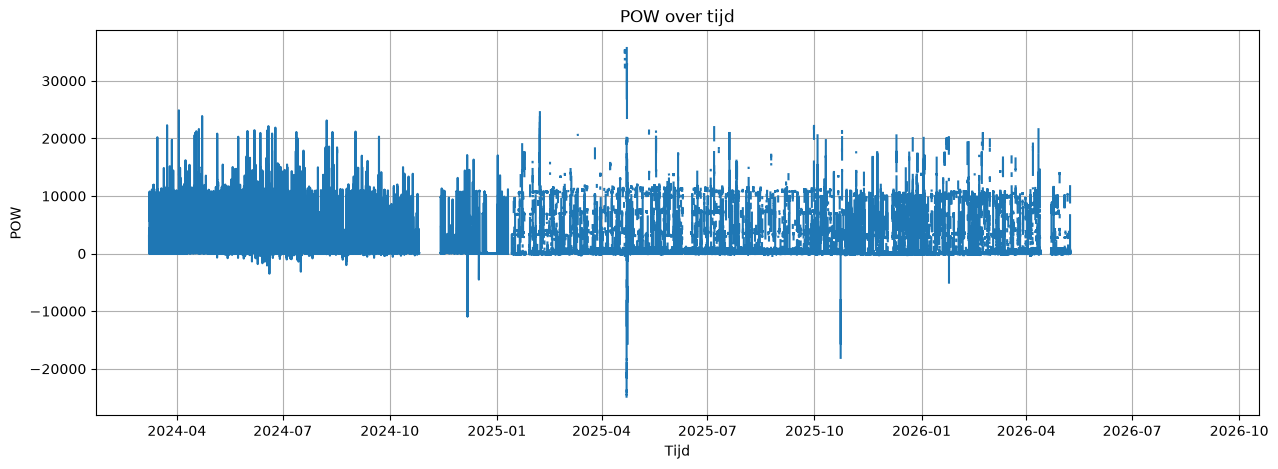

In [13]:
# POW plotten tegenover tijd
plt.figure(figsize=(15, 5))
plt.plot(df_totaal["timestamp"], df_totaal["POW"])

plt.xlabel("Tijd")
plt.ylabel("POW")
plt.title("POW over tijd")
plt.grid()
plt.show()

In [14]:
print("Eerste timestamp:", df_totaal["timestamp"].min())
print("Laatste timestamp:", df_totaal["timestamp"].max())

print(
    "Laatste timestamp met geldige POW:",
    df_totaal.loc[df_totaal["POW"].notna(), "timestamp"].max()
)

Eerste timestamp: 2024-03-08 01:00:00+01:00
Laatste timestamp: 2026-09-07 08:05:00+02:00
Laatste timestamp met geldige POW: 2026-09-02 08:10:00+02:00


In [15]:
df_carport_pow = df_carport[
    df_carport["POW"].notna()
].copy()

In [16]:
controle_pow = (
    df_carport_pow
    .groupby(
        [
            "timestamp",
            "CTYPE",
            "CTYPEC",
            "ENAME",
            "ETYPE"
        ],
        dropna=False
    )
    .agg(
        aantal_rijen=("POW", "size"),
        aantal_unieke_POW=("POW", "nunique"),
        min_POW=("POW", "min"),
        max_POW=("POW", "max")
    )
    .reset_index()
)

controle_pow = controle_pow[
    controle_pow["aantal_rijen"] > 1
]

controle_pow.head(50)

,timestamp,CTYPE,CTYPEC,ENAME,ETYPE,aantal_rijen,aantal_unieke_POW,min_POW,max_POW
468204,2024-10-05 20:10:00+02:00,electricity,consumption,totaalverbruik-e4393cd3dfdb,powermeter,2,2,3646.764706,4056.000000
468205,2024-10-05 20:10:00+02:00,electricity,generation,zonnepanelen-e4393cd3dfdb,solarpanel,2,2,-7242.800000,-23.500000
468206,2024-10-05 20:10:00+02:00,electricity,supply,hoofdaansluiting-e4393cd3dfdb,powermeter,2,2,927.071429,4033.400000
468207,2024-10-05 20:10:00+02:00,electricity,NaN,laadpaal1-e4393cd3dfdb,evcharger,2,2,3979.625000,4082.363636
468208,2024-10-05 20:10:00+02:00,electricity,NaN,laadpaal2-e4393cd3dfdb,evcharger,2,2,0.000250,0.000313
468209,2024-10-05 20:10:00+02:00,electricity,NaN,laadpaal3-e4393cd3dfdb,evcharger,2,2,0.000340,0.000389
468212,2024-10-05 20:10:00+02:00,electricity,NaN,overigverbruik-e4393cd3dfdb,powermeter,2,2,-26.057143,-11.382022
468213,2024-10-05 20:10:00+02:00,electricity,NaN,wijktotaalverbruik-e4393cd3dfdb,powermeter,2,2,9630.992593,10295.836735
468214,2024-10-05 20:10:00+02:00,electricity,NaN,wijktotaleopwek-e4393cd3dfdb,powermeter,2,2,-12257.200000,-23.500000
468215,2024-10-05 20:10:00+02:00,electricity,NaN,wijkvirtuelehoofdmeter-e4393cd3dfdb,powermeter,2,2,9157.367647,10230.265306


### Punt 3 check?

In [17]:
#Alleen rijen waar POW aanwezig is
df_pow = df_carport[df_carport["POW"].notna()].copy()

#Zoektype van Pieter
filter = ["timestamp", "CTYPE", "CTYPEC", "ENAME", "ETYPE"]

dubbel = df_pow.duplicated(subset=filter,keep=False)

dubbele_pow = (df_pow.loc[dubbel].sort_values(filter))

dubbele_pow

,timestamp,CO2EQ,CTYPE,ENAME,ETYPE,source_zip,source_csv,source_folder,CTYPEC,ESTYPE,...,CO2_EXP,CO2_IMP,ENE_EXP,ENE_IMP,COST,COST_EXP,COST_IMP,ENE_CNT_EXP,ENE_CNT_IMP,PRICE
527103,2024-10-05 20:10:00+02:00,NaN,electricity,totaalverbruik-e4393cd3dfdb,powermeter,241005_totaalverbruik-e4393cd3dfdb_182475cc0ac...,241005_totaalverbruik-e4393cd3dfdb_182475cc0ac...,totaalverbruik-e4393cd3dfdb,consumption,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
527104,2024-10-05 20:10:00+02:00,NaN,electricity,totaalverbruik-e4393cd3dfdb,powermeter,241005_totaalverbruik-e4393cd3dfdb_182475cc0ac...,241005_totaalverbruik-e4393cd3dfdb_182475cc0ac...,totaalverbruik-e4393cd3dfdb,consumption,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
527111,2024-10-05 20:10:00+02:00,NaN,electricity,zonnepanelen-e4393cd3dfdb,solarpanel,241005_zonnepanelen-e4393cd3dfdb_c5163d01ee033...,241005_zonnepanelen-e4393cd3dfdb_c5163d01ee033...,zonnepanelen-e4393cd3dfdb,generation,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
527112,2024-10-05 20:10:00+02:00,NaN,electricity,zonnepanelen-e4393cd3dfdb,solarpanel,241005_zonnepanelen-e4393cd3dfdb_c5163d01ee033...,241005_zonnepanelen-e4393cd3dfdb_c5163d01ee033...,zonnepanelen-e4393cd3dfdb,generation,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
527091,2024-10-05 20:10:00+02:00,NaN,electricity,hoofdaansluiting-e4393cd3dfdb,powermeter,241005_hoofdaansluiting-e4393cd3dfdb_182475cc0...,241005_hoofdaansluiting-e4393cd3dfdb_182475cc0...,hoofdaansluiting-e4393cd3dfdb,supply,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
527092,2024-10-05 20:10:00+02:00,NaN,electricity,hoofdaansluiting-e4393cd3dfdb,powermeter,241005_hoofdaansluiting-e4393cd3dfdb_182475cc0...,241005_hoofdaansluiting-e4393cd3dfdb_182475cc0...,hoofdaansluiting-e4393cd3dfdb,supply,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
527093,2024-10-05 20:10:00+02:00,NaN,electricity,laadpaal1-e4393cd3dfdb,evcharger,241005_laadpaal1-e4393cd3dfdb_8f02b76d3db51938...,241005_laadpaal1-e4393cd3dfdb_8f02b76d3db51938...,laadpaal1-e4393cd3dfdb,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
527094,2024-10-05 20:10:00+02:00,NaN,electricity,laadpaal1-e4393cd3dfdb,evcharger,241005_laadpaal1-e4393cd3dfdb_8f02b76d3db51938...,241005_laadpaal1-e4393cd3dfdb_8f02b76d3db51938...,laadpaal1-e4393cd3dfdb,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
527095,2024-10-05 20:10:00+02:00,NaN,electricity,laadpaal2-e4393cd3dfdb,evcharger,241005_laadpaal2-e4393cd3dfdb_8f02b76d3db51938...,241005_laadpaal2-e4393cd3dfdb_8f02b76d3db51938...,laadpaal2-e4393cd3dfdb,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
527096,2024-10-05 20:10:00+02:00,NaN,electricity,laadpaal2-e4393cd3dfdb,evcharger,241005_laadpaal2-e4393cd3dfdb_8f02b76d3db51938...,241005_laadpaal2-e4393cd3dfdb_8f02b76d3db51938...,laadpaal2-e4393cd3dfdb,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [18]:
kolommen = [
    "timestamp",
    "CTYPE",
    "CTYPEC",
    "ENAME",
    "ETYPE",
    "POW"
]

dubbele_pow[kolommen].head(50)

,timestamp,CTYPE,CTYPEC,ENAME,ETYPE,POW
527103,2024-10-05 20:10:00+02:00,electricity,consumption,totaalverbruik-e4393cd3dfdb,powermeter,3646.764706
527104,2024-10-05 20:10:00+02:00,electricity,consumption,totaalverbruik-e4393cd3dfdb,powermeter,4056.000000
527111,2024-10-05 20:10:00+02:00,electricity,generation,zonnepanelen-e4393cd3dfdb,solarpanel,-7242.800000
527112,2024-10-05 20:10:00+02:00,electricity,generation,zonnepanelen-e4393cd3dfdb,solarpanel,-23.500000
527091,2024-10-05 20:10:00+02:00,electricity,supply,hoofdaansluiting-e4393cd3dfdb,powermeter,927.071429
527092,2024-10-05 20:10:00+02:00,electricity,supply,hoofdaansluiting-e4393cd3dfdb,powermeter,4033.400000
527093,2024-10-05 20:10:00+02:00,electricity,NaN,laadpaal1-e4393cd3dfdb,evcharger,3979.625000
527094,2024-10-05 20:10:00+02:00,electricity,NaN,laadpaal1-e4393cd3dfdb,evcharger,4082.363636
527095,2024-10-05 20:10:00+02:00,electricity,NaN,laadpaal2-e4393cd3dfdb,evcharger,0.000313
527096,2024-10-05 20:10:00+02:00,electricity,NaN,laadpaal2-e4393cd3dfdb,evcharger,0.000250
